In [27]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
filepath='/content/drive/MyDrive/Ict_files/Student_Depression_Dataset.csv'
df=pd.read_csv(filepath)

EDA

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [30]:
df.shape

(4464, 13)

In [31]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [32]:
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [33]:
df.size

58032

In [34]:
df.tail()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No
4463,Female,21,Lower Middle class,Single,Unmarried,Family,5,2.56,Yes,Abnormal,4000,Barisal,Yes


In [35]:
df.sample(5)

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
3189,Male,25,Middle class,Single,Unmarried,Bachelor,3,2.54,No,Normal,8800,Barisal,No
3642,Female,18,Lower Middle class,In a Relationship,Married,Family,5,3.60,No,Abnormal,6500,Rajshahi,No
3354,Male,22,Lower Middle class,Single,Unmarried,Bachelor,11,2.65,Yes,Abnormal,5900,Rangpur,Yes
3653,Female,20,Lower Middle class,In a Relationship,Unmarried,Bachelor,8,3.60,Yes,Normal,9856,Chittagong,No
365,Female,20,Lower Middle class,Single,Unmarried,Bachelor,5,3.70,Yes,Good,9842,Khulna,No


In [36]:
df.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='object')

In [37]:
df.dtypes

,0
Gender,object
Age,int64
Family_background,object
Relationship_status,object
Marital_status,object
Living_style,object
Current_semester,int64
CGPA,float64
friend_circle,object
Health_condition,object


In [38]:
df.index

RangeIndex(start=0, stop=4464, step=1)

In [39]:
num_cols= df.select_dtypes(include=['number']).columns
print(num_cols)

Index(['Age', 'Current_semester', 'CGPA', 'Cost_without_study'], dtype='object')


In [40]:
cat_cols= df.select_dtypes(include=['object']).columns
print(cat_cols)

Index(['Gender', 'Family_background', 'Relationship_status', 'Marital_status',
       'Living_style', 'friend_circle', 'Health_condition', 'Home_division',
       'Depression'],
      dtype='object')


## **Preprocessing**

DATA FRAME -> Num_df -> missing values , duplicates , standardization

DATA FRAME -> Cat_df -> missing values , duplicates , Encoding

In [41]:
df.isna().sum()

,0
Gender,0
Age,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
Current_semester,0
CGPA,0
friend_circle,0
Health_condition,0


In [42]:
df.duplicated().sum()

np.int64(0)

In [43]:
df[cat_cols].isna().sum()

,0
Gender,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
friend_circle,0
Health_condition,0
Home_division,0
Depression,0


Outlier handling

In [44]:
df.shape

(4464, 13)

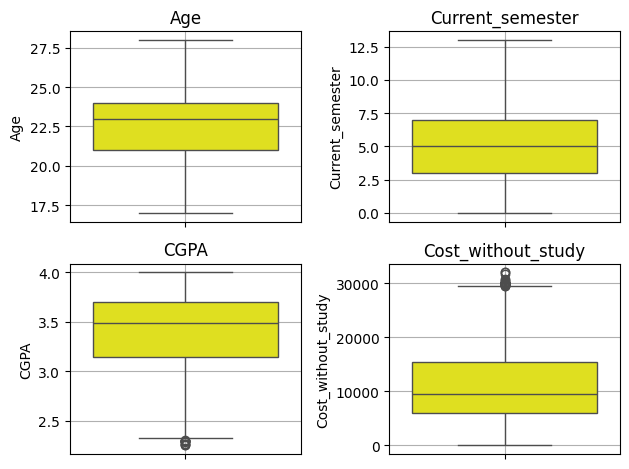

In [45]:

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col],color='yellow')
    plt.title(col)
    plt.grid()
plt.tight_layout()
plt.show()

In [46]:
Q1= df[num_cols].quantile(0.25)
Q3= df[num_cols].quantile(0.75)
IQR = Q3 - Q1
print(Q1)
print(Q3)
print(IQR)

upper_limit = Q3 + (1.5 * IQR)
lower_limit = Q1 - (1.5 * IQR)

#fetching outliers
outliers = (df[num_cols]> upper_limit) | (df[num_cols]<lower_limit)
print(outliers)

#method 1 removing outliers
df = df[~outliers.any(axis=1)]
# #method 1.1
# df_beer_without_outliers = ((df_beer[num_cols]<= upper_limit) & (df_beer[num_cols]>=lower_limit))


Age                     21.00
Current_semester         3.00
CGPA                     3.15
Cost_without_study    6100.00
Name: 0.25, dtype: float64
Age                      24.0
Current_semester          7.0
CGPA                      3.7
Cost_without_study    15439.0
Name: 0.75, dtype: float64
Age                      3.00
Current_semester         4.00
CGPA                     0.55
Cost_without_study    9339.00
dtype: float64
        Age  Current_semester   CGPA  Cost_without_study
0     False             False  False               False
1     False             False  False               False
2     False             False  False               False
3     False             False  False               False
4     False             False  False               False
...     ...               ...    ...                 ...
4459  False             False  False               False
4460  False             False  False               False
4461  False             False  False               False
4

In [47]:
df[num_cols] = df[num_cols].clip(lower=lower_limit,
                                upper=upper_limit,
                                axis=1)

In [48]:
df.shape

(4416, 13)

Label encoding

In [49]:
df['Depression'].unique()

array(['Yes', 'No'], dtype=object)

In [50]:
#label encoding
label_encoder = LabelEncoder()
df['Depression'] = label_encoder.fit_transform(df['Depression'])
df['Depression'].unique()

array([1, 0])

In [51]:
df['Depression'].head(10)

,Depression
0,1
1,1
2,1
3,0
4,1
5,0
6,0
7,1
8,1
9,0


Ordinal encoding

In [52]:
df['Health_condition'].unique()

array(['Critical', 'Abnormal', 'Good', 'Normal'], dtype=object)

In [53]:
encoder_health = OrdinalEncoder(
    categories = [['Normal', 'Good', 'Abnormal', 'Critical']]
)

df['Health_condition'] = encoder_health.fit_transform(df[['Health_condition']])
print(df['Health_condition'])
df.head()

0       3.0
1       2.0
2       2.0
3       1.0
4       2.0
       ... 
4459    3.0
4460    0.0
4461    1.0
4462    0.0
4463    2.0
Name: Health_condition, Length: 4416, dtype: float64


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113,Chittagong,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815,Chittagong,1
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,2.0,15450,Dhaka,1
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,1.0,17413,Dhaka,0
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,2.0,16693,Dhaka,1


In [54]:
df['Family_background'].unique()

array(['Middle class', 'Lower Middle class', 'Rich class'], dtype=object)

In [55]:
encoder_family = OrdinalEncoder(
    categories = [['Lower Middle class', 'Middle class', 'Rich class']])

df['Family_background'] = encoder_family.fit_transform(df[['Family_background']])
print(df['Family_background'])
df.head()

0       1.0
1       1.0
2       1.0
3       1.0
4       1.0
       ... 
4459    1.0
4460    0.0
4461    1.0
4462    1.0
4463    0.0
Name: Family_background, Length: 4416, dtype: float64


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,1.0,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113,Chittagong,1
1,Male,19,1.0,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815,Chittagong,1
2,Male,23,1.0,Single,Unmarried,Family,8,3.28,No,2.0,15450,Dhaka,1
3,Male,20,1.0,Complicated,Unmarried,Family,2,3.77,No,1.0,17413,Dhaka,0
4,Female,21,1.0,Single,Unmarried,Family,1,4.00,No,2.0,16693,Dhaka,1


One Hot Encoding

In [56]:
encoder_gender = OneHotEncoder()

encoded_data = encoder_gender.fit_transform(df[['Gender']])

In [57]:
#to convert to pandas dataframe

encoded_df = pd.DataFrame(
    encoded_data.toarray(),
    columns = encoder_gender.get_feature_names_out(['Gender']),
    index = df.index
)

encoded_df.head()

,Gender_Female,Gender_Male
0,1.0,0.0
1,0.0,1.0
2,0.0,1.0
3,0.0,1.0
4,1.0,0.0


In [58]:
df = pd.concat([df.drop('Gender', axis=1), encoded_df], axis=1)

In [59]:
df.head()

,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male
0,22,1.0,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113,Chittagong,1,1.0,0.0
1,19,1.0,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815,Chittagong,1,0.0,1.0
2,23,1.0,Single,Unmarried,Family,8,3.28,No,2.0,15450,Dhaka,1,0.0,1.0
3,20,1.0,Complicated,Unmarried,Family,2,3.77,No,1.0,17413,Dhaka,0,0.0,1.0
4,21,1.0,Single,Unmarried,Family,1,4.00,No,2.0,16693,Dhaka,1,1.0,0.0


In [60]:
df['Relationship_status'].unique()

array(['Single', 'Complicated', 'In a Relationship'], dtype=object)

In [61]:
encoder_relation = OneHotEncoder()

encoded_data1 = encoder_relation.fit_transform(df[['Relationship_status']])

encoded_df = pd.DataFrame(
    encoded_data1.toarray(),
    columns = encoder_relation.get_feature_names_out(['Relationship_status']),
    index = df.index
)

encoded_df.head()

,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single
0,0.0,0.0,1.0
1,0.0,0.0,1.0
2,0.0,0.0,1.0
3,1.0,0.0,0.0
4,0.0,0.0,1.0


In [62]:
df = pd.concat([df.drop('Relationship_status', axis=1), encoded_df], axis=1)

In [63]:
df.head()

,Age,Family_background,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single
0,22,1.0,Unmarried,Bachelor,8,3.43,Yes,3.0,10113,Chittagong,1,1.0,0.0,0.0,0.0,1.0
1,19,1.0,Unmarried,Bachelor,2,3.70,Yes,2.0,13815,Chittagong,1,0.0,1.0,0.0,0.0,1.0
2,23,1.0,Unmarried,Family,8,3.28,No,2.0,15450,Dhaka,1,0.0,1.0,0.0,0.0,1.0
3,20,1.0,Unmarried,Family,2,3.77,No,1.0,17413,Dhaka,0,0.0,1.0,1.0,0.0,0.0
4,21,1.0,Unmarried,Family,1,4.00,No,2.0,16693,Dhaka,1,1.0,0.0,0.0,0.0,1.0


In [64]:
df['Marital_status'].unique()

array(['Unmarried', 'Married', 'Separated'], dtype=object)

In [65]:
encoder_marital = OneHotEncoder()

encoded_data2 = encoder_marital.fit_transform(df[['Marital_status']])

encoded_df = pd.DataFrame(
    encoded_data2.toarray(),
    columns = encoder_marital.get_feature_names_out(['Marital_status']),
    index = df.index
)

encoded_df.head()

df = pd.concat([df.drop('Marital_status', axis=1), encoded_df], axis=1)


In [66]:
df.sample(10)

,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried
3051,23,1.0,Family,5,2.53,No,1.0,4100,Rangpur,0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1099,24,1.0,Bachelor,4,3.00,No,1.0,16375,Chittagong,0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
2594,22,1.0,Family,2,3.00,Yes,2.0,10000,Khulna,0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
492,26,1.0,Bachelor,7,3.67,Yes,3.0,11955,Khulna,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
204,26,2.0,Bachelor,5,3.33,Yes,2.0,25900,Dhaka,0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2934,23,1.0,Family,6,2.69,No,0.0,9100,Dhaka,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2186,23,1.0,Bachelor,4,3.02,Yes,0.0,9400,Sylhet,0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
759,26,1.0,Bachelor,6,4.00,No,2.0,13645,Khulna,0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2948,23,1.0,Family,8,3.59,No,2.0,8800,Barisal,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
715,20,0.0,Bachelor,3,4.00,Yes,3.0,6071,Rajshahi,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


In [67]:
df['Living_style'].unique()

array(['Bachelor', 'Family'], dtype=object)

In [68]:
encoder_living = OneHotEncoder()

encoded_data3 = encoder_living.fit_transform(df[['Living_style']])

encoded_df = pd.DataFrame(
    encoded_data3.toarray(),
    columns = encoder_living.get_feature_names_out(['Living_style']),
    index = df.index
)

encoded_df.head()

df = pd.concat([df.drop('Living_style', axis=1), encoded_df], axis=1)

In [69]:
df.head()

,Age,Family_background,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried,Living_style_Bachelor,Living_style_Family
0,22,1.0,8,3.43,Yes,3.0,10113,Chittagong,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
1,19,1.0,2,3.70,Yes,2.0,13815,Chittagong,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
2,23,1.0,8,3.28,No,2.0,15450,Dhaka,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
3,20,1.0,2,3.77,No,1.0,17413,Dhaka,0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,21,1.0,1,4.00,No,2.0,16693,Dhaka,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0


In [70]:
df['friend_circle'].unique()

array(['Yes', 'No'], dtype=object)

In [71]:
encoder_friend = OneHotEncoder()

encoded_data4 = encoder_friend.fit_transform(df[['friend_circle']])

encoded_df = pd.DataFrame(
    encoded_data4.toarray(),
    columns = encoder_friend.get_feature_names_out(['friend_circle']),
    index = df.index
)

encoded_df.head()

df = pd.concat([df.drop('friend_circle', axis=1), encoded_df], axis=1)

In [72]:
df.head()

,Age,Family_background,Current_semester,CGPA,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried,Living_style_Bachelor,Living_style_Family,friend_circle_No,friend_circle_Yes
0,22,1.0,8,3.43,3.0,10113,Chittagong,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
1,19,1.0,2,3.70,2.0,13815,Chittagong,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
2,23,1.0,8,3.28,2.0,15450,Dhaka,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
3,20,1.0,2,3.77,1.0,17413,Dhaka,0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
4,21,1.0,1,4.00,2.0,16693,Dhaka,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0


In [73]:
df['Home_division'].unique()

array(['Chittagong', 'Dhaka', 'Rajshahi', 'Mymensingh', 'Barisal',
       'Rangpur', 'Khulna', 'Sylhet'], dtype=object)

In [74]:
encoder_home = OneHotEncoder()

encoded_data5 = encoder_home.fit_transform(df[['Home_division']])

encoded_df = pd.DataFrame(
    encoded_data5.toarray(),
    columns = encoder_home.get_feature_names_out(['Home_division']),
    index = df.index
)

encoded_df.head()

df = pd.concat([df.drop('Home_division', axis=1), encoded_df], axis=1)

In [75]:
df.head()

,Age,Family_background,Current_semester,CGPA,Health_condition,Cost_without_study,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,...,friend_circle_No,friend_circle_Yes,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,22,1.0,8,3.43,3.0,10113,1,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,19,1.0,2,3.70,2.0,13815,1,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,23,1.0,8,3.28,2.0,15450,1,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,20,1.0,2,3.77,1.0,17413,0,0.0,1.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,21,1.0,1,4.00,2.0,16693,1,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [77]:
print(num_cols)

Index(['Age', 'Current_semester', 'CGPA', 'Cost_without_study'], dtype='object')


Feature scaling

In [79]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df[num_cols] = scaler.fit_transform(df[num_cols])
df.head()
df[num_cols].mean()

,0
Age,4.505253e-17
Current_semester,-1.287215e-17
CGPA,0.000000e+00
Cost_without_study,-1.287215e-17


In [80]:
df[num_cols].std()

,0
Age,1.000113
Current_semester,1.000113
CGPA,1.000113
Cost_without_study,1.000113
